
# PCD Assignment 03
## Image Segmentation and Morphological Processing

**Name:** Mazaya Nurina  
**NIM:** 25/554758/PA/23236

**Segmentation Method:** Otsu's Thresholding  
**Morphological Operations:** Erosion, Dilation, Opening, and Closing

### Objective
The objective of this assignment is to implement an image segmentation method and several morphological operations from scratch without using built-in image-processing functions. The segmentation results before and after applying morphological processing will be compared to observe differences in noise removal, object boundaries, and overall segmentation quality.

### Methodology
1. Prepare a grayscale image.
2. Implement Otsu's thresholding manually.
3. Apply erosion, dilation, opening, and closing using a 3 × 3 structuring element.
4. Compare the segmentation results before and after morphological processing.
5. Analyze the results and draw a conclusion.


In [9]:

import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")


Libraries imported successfully.


Saving ricegrain.jpg to ricegrain.jpg


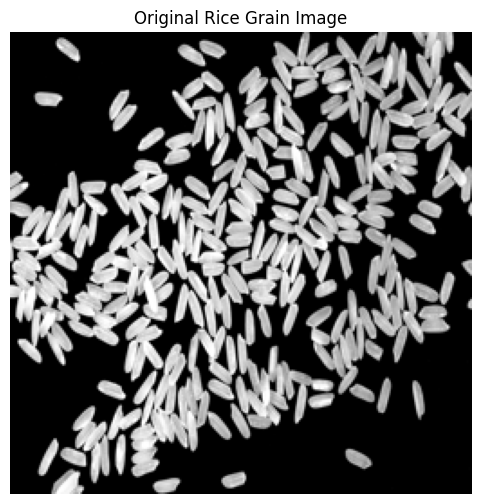

Image loaded successfully!
Image dimensions: (256, 256)


In [10]:

# Upload the rice grain image
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

# Read the uploaded image
original_image = Image.open(
    io.BytesIO(uploaded["ricegrain.jpg"])
).convert("L")

# Resize for faster manual processing
original_image = original_image.resize((256, 256))

# Convert to NumPy array
image = np.array(original_image, dtype=np.uint8)

# Display the grayscale image
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Rice Grain Image")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Image dimensions:", image.shape)


### Image Segmentation Using Otsu's Thresholding

Image segmentation is the process of dividing an image into meaningful regions or objects. In this assignment, Otsu's thresholding is used to separate foreground objects from the background.

Otsu's method automatically determines an optimal threshold by maximizing the between-class variance:

$$\sigma_b^2(t) = w_0(t)w_1(t)[\mu_0(t)-\mu_1(t)]^2$$

where:
- $w_0$ and $w_1$ are the probabilities of background and foreground pixels.
- $\mu_0$ and $\mu_1$ are their respective mean intensities.
- $t$ is the candidate threshold.

Pixels above the selected threshold are classified as foreground (1), while the remaining pixels are classified as background (0).

Otsu Threshold: 101


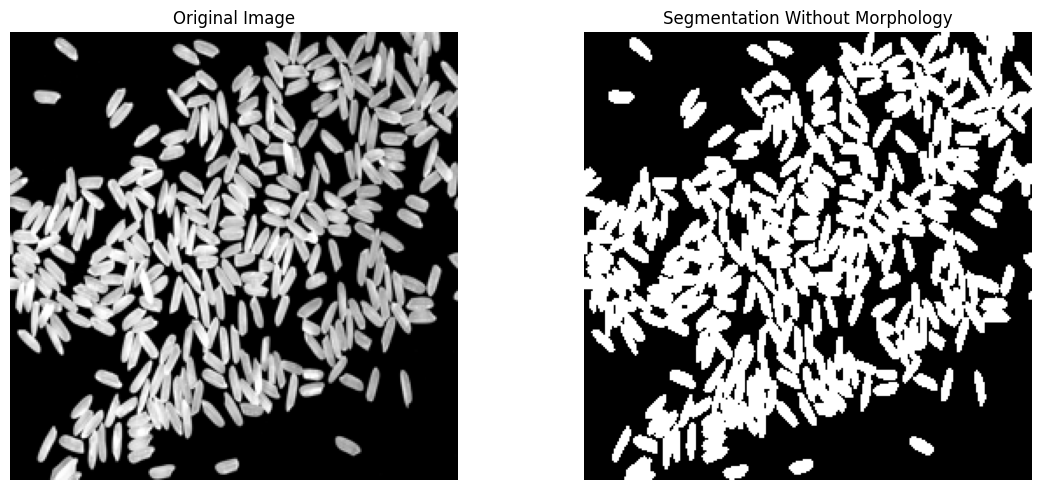

In [11]:

def otsu_threshold(image):
    # Calculate histogram manually
    histogram = np.zeros(256, dtype=np.int64)

    for pixel in image.flat:
        histogram[int(pixel)] += 1

    total_pixels = image.size
    total_sum = 0

    for i in range(256):
        total_sum += i * histogram[i]

    weight_background = 0
    sum_background = 0
    max_variance = -1
    best_threshold = 0

    for t in range(256):
        weight_background += histogram[t]
        sum_background += t * histogram[t]

        if weight_background == 0:
            continue

        weight_foreground = total_pixels - weight_background

        if weight_foreground == 0:
            break

        mean_background = sum_background / weight_background
        mean_foreground = (
            total_sum - sum_background
        ) / weight_foreground

        variance = (
            weight_background * weight_foreground *
            (mean_background - mean_foreground)**2
        )

        if variance > max_variance:
            max_variance = variance
            best_threshold = t

    return best_threshold


threshold = otsu_threshold(image)

# Apply binary segmentation manually
segmented = np.zeros(image.shape, dtype=np.uint8)

for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        if image[i, j] > threshold:
            segmented[i, j] = 1
        else:
            segmented[i, j] = 0

print("Otsu Threshold:", threshold)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='gray', vmin=0, vmax=1)
plt.title("Segmentation Without Morphology")
plt.axis("off")

plt.tight_layout()
plt.show()


### Morphological Processing

Morphological processing modifies the shape and structure of objects in a binary image using a structuring element. In this assignment, a 3 × 3 square structuring element is used.

**Erosion:** Shrinks foreground objects and removes small foreground noise.

**Dilation:** Expands foreground objects and can connect nearby regions.

**Opening:** Erosion followed by dilation. It is useful for removing small foreground noise.

**Closing:** Dilation followed by erosion. It is useful for filling small holes and gaps.

All morphological operations are implemented manually using loops, without built-in morphology functions.

In [12]:

# 3x3 square structuring element
kernel = np.ones((3, 3), dtype=np.uint8)

def erosion(binary_image, kernel):
    h, w = binary_image.shape
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    output = np.zeros((h, w), dtype=np.uint8)

    for i in range(h):
        for j in range(w):
            fits = True

            for ki in range(kh):
                for kj in range(kw):
                    if kernel[ki, kj] == 0:
                        continue

                    x = i + ki - pad_h
                    y = j + kj - pad_w

                    # Outside-image pixels are background
                    if x < 0 or x >= h or y < 0 or y >= w:
                        fits = False
                        break

                    if binary_image[x, y] == 0:
                        fits = False
                        break

                if not fits:
                    break

            if fits:
                output[i, j] = 1

    return output


def dilation(binary_image, kernel):
    h, w = binary_image.shape
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    output = np.zeros((h, w), dtype=np.uint8)

    for i in range(h):
        for j in range(w):
            found = False

            for ki in range(kh):
                for kj in range(kw):
                    if kernel[ki, kj] == 0:
                        continue

                    x = i + ki - pad_h
                    y = j + kj - pad_w

                    if 0 <= x < h and 0 <= y < w:
                        if binary_image[x, y] == 1:
                            found = True
                            break

                if found:
                    break

            if found:
                output[i, j] = 1

    return output


def opening(binary_image, kernel):
    eroded = erosion(binary_image, kernel)
    return dilation(eroded, kernel)


def closing(binary_image, kernel):
    dilated = dilation(binary_image, kernel)
    return erosion(dilated, kernel)


print("Morphological functions created successfully.")


Morphological functions created successfully.


In [13]:

eroded_image = erosion(segmented, kernel)
dilated_image = dilation(segmented, kernel)
opened_image = opening(segmented, kernel)
closed_image = closing(segmented, kernel)

# Opening removes small bright noise.
# Closing fills small dark holes.
processed_image = closing(opened_image, kernel)

print("All morphological operations completed.")


All morphological operations completed.


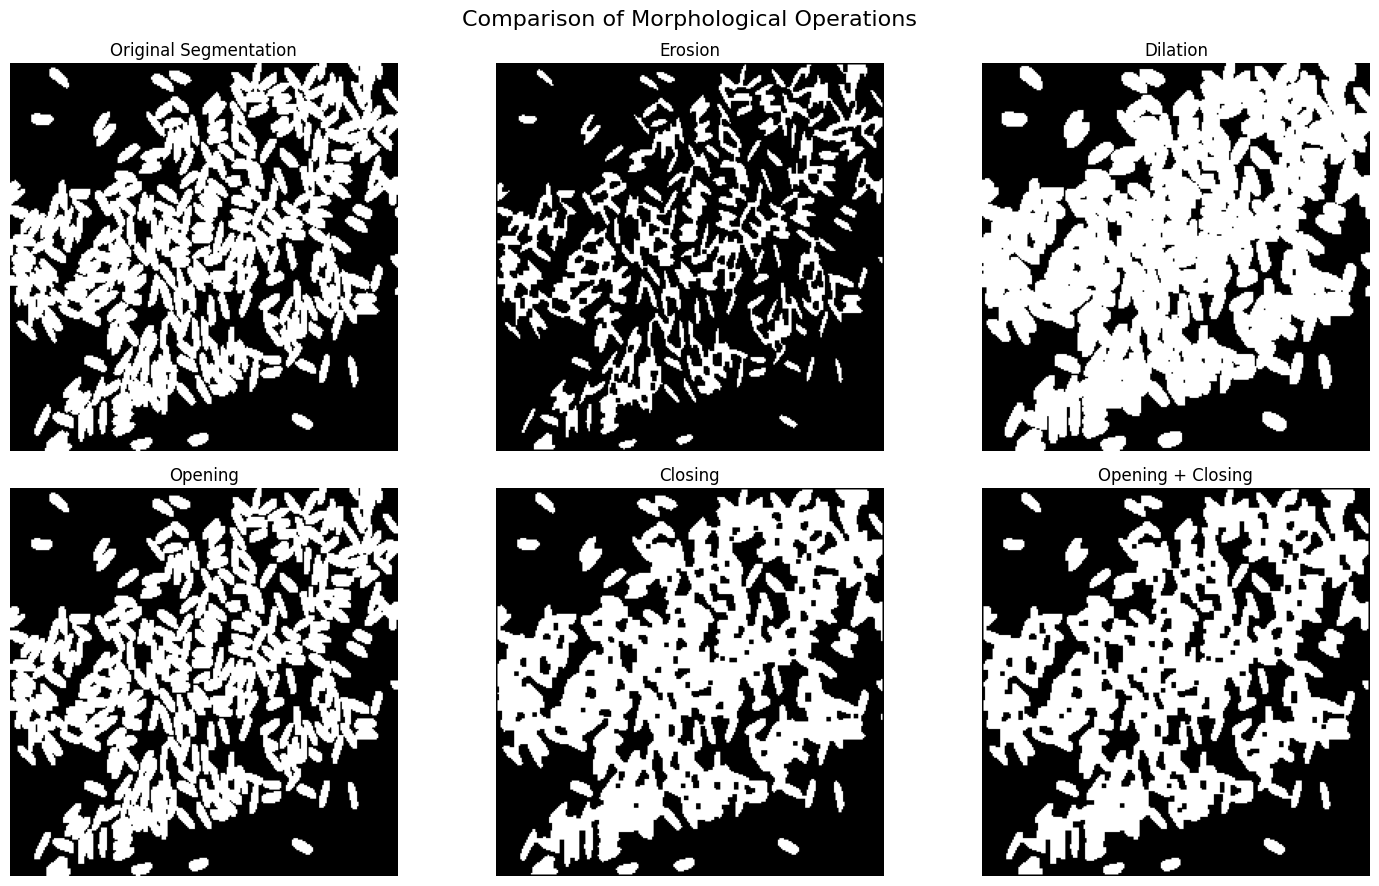

In [14]:

images = [
    segmented,
    eroded_image,
    dilated_image,
    opened_image,
    closed_image,
    processed_image
]

titles = [
    "Original Segmentation",
    "Erosion",
    "Dilation",
    "Opening",
    "Closing",
    "Opening + Closing"
]

plt.figure(figsize=(15, 9))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=1)
    plt.title(titles[i])
    plt.axis("off")

plt.suptitle("Comparison of Morphological Operations", fontsize=16)
plt.tight_layout()
plt.show()


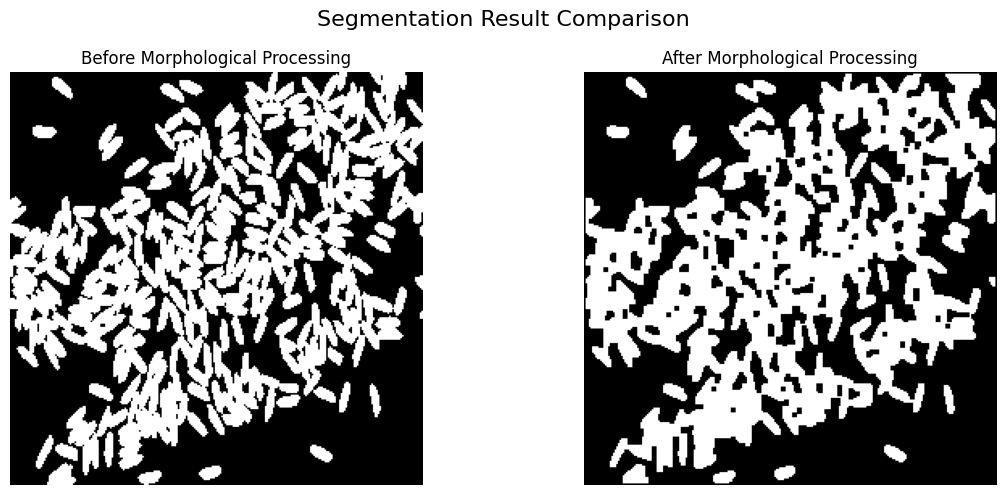

Foreground pixels before: 27066
Foreground pixels after : 28549
Pixels changed          : 2687


In [15]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(segmented, cmap='gray', vmin=0, vmax=1)
plt.title("Before Morphological Processing")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image, cmap='gray', vmin=0, vmax=1)
plt.title("After Morphological Processing")
plt.axis("off")

plt.suptitle("Segmentation Result Comparison", fontsize=16)
plt.tight_layout()
plt.show()

# Count foreground pixels
before_pixels = np.sum(segmented)
after_pixels = np.sum(processed_image)

# Count changed pixels
changed_pixels = np.sum(segmented != processed_image)

print("Foreground pixels before:", before_pixels)
print("Foreground pixels after :", after_pixels)
print("Pixels changed          :", changed_pixels)



### Results and Discussion

The rice grain image was segmented using Otsu's thresholding, which automatically determined a threshold value of 101. The initial segmentation successfully separated many rice grains from the darker background, although some grains were touching and small gaps remained within the foreground regions.

Four morphological operations were implemented manually. Erosion reduced foreground regions, while dilation expanded them. Opening helped remove small foreground details, whereas closing filled small gaps and connected nearby foreground regions.

After applying opening followed by closing, the number of foreground pixels increased from 27,066 to 28,549, with 2,687 pixels changing their classification. The final result showed more continuous foreground regions. However, some neighboring rice grains became connected, making individual grains less distinguishable.

Therefore, morphological processing improved the continuity of the segmented regions but also affected object separation. This demonstrates that the effectiveness of morphological processing depends on the characteristics of the image and the selected structuring element.



### Conclusion

In this assignment, Otsu's thresholding and four morphological operations, namely erosion, dilation, opening, and closing, were successfully implemented manually without using built-in image-processing functions.

Otsu's thresholding separated the rice grains from the background using a threshold value of 101. Applying morphological processing modified the binary segmentation by removing small details and filling gaps.

The comparison showed that morphological processing produced more continuous foreground regions, although some adjacent rice grains became connected. Therefore, morphological processing can refine segmentation results, but its effectiveness depends on the structuring element and the desired segmentation outcome.
